# TRỢ LÝ HỎI ĐÁP: HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI Ý ĐỊNH (phần mở rộng)

**Mã sinh viên:** 2324801030095 · **Họ và tên:** Nguyễn Quang Long · **Lớp:** D23KTPM01 · **Môn:** Học máy

Trợ lý trên trang demo phải hiểu người dùng muốn gì: định giá nhà, tìm nhà, hỏi giá thuê, hỏi pháp lý… Bản cũ dùng **luật từ khóa** viết tay: câu nào khớp mẫu thì hiểu, khác cách diễn đạt một chút là không hiểu. Notebook này thay bằng **mô hình học có giám sát**:

- **T (nhiệm vụ):** phân loại một câu hỏi tiếng Việt vào 1 trong 19 ý định (gồm cả "ngoài phạm vi").
- **E (kinh nghiệm):** bộ câu hỏi có gán nhãn ý định (`data/tro_ly/cau_hoi_huan_luyen.csv`).
- **P (độ đo):** độ chính xác và F1 trung bình các lớp trên **tập kiểm tra viết riêng** (`data/tro_ly/cau_hoi_kiem_tra.csv`): câu không dấu, viết tắt, sai chính tả, cách hỏi khác hẳn tập huấn luyện.

**Lưu ý trung thực:** các câu hỏi do người làm đề tài **viết tay** để mô tả cách người dùng có thể hỏi; chưa có nhật ký câu hỏi thật của người dùng. Phần **trả lời** của trợ lý vẫn lấy số liệu từ dữ liệu và mô hình định giá thật của đề tài.

Liên hệ môn học: phân loại văn bản bằng TF-IDF (bài thực hành TH6), học có giám sát, chia train/test, kiểm định chéo, so sánh với mốc (luật cũ).

**Phạm vi kiến thức** (toàn bộ notebook này là **phần mở rộng** của đề tài; notebook chính `2324801030095.ipynb` mới là bài làm theo môn học):

| Trong môn học (bài giảng / thực hành) | Ngoài môn học (nâng cao) |
|---|---|
| Học có giám sát trên văn bản (TH6, TH9, TH11): tách từ, TF-IDF, Naive Bayes, Logistic Regression, SVM tuyến tính; kiểm định chéo K-fold phân tầng; độ chính xác (accuracy), F1, ma trận nhầm lẫn | TF-IDF n-gram ký tự (chịu được viết không dấu/viết tắt); kết hợp mô hình với luật và ngưỡng hỏi lại τ chọn bằng dự đoán ngoài-fold; chạy lại mô hình bằng JavaScript trên trình duyệt |

In [1]:
import re, subprocess, shutil, unicodedata, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DL, MODEL_DIR = GOC / "data" / "tro_ly", GOC / "model"
RANDOM_STATE = 42

train = pd.read_csv(DL / "cau_hoi_huan_luyen.csv")
test = pd.read_csv(DL / "cau_hoi_kiem_tra.csv")
print(f"Tập huấn luyện: {len(train)} câu · tập kiểm tra: {len(test)} câu · {train['y_dinh'].nunique()} ý định")
pd.DataFrame({"Huấn luyện": train["y_dinh"].value_counts(), "Kiểm tra": test["y_dinh"].value_counts()}).fillna(0).astype(int)

Tập huấn luyện: 410 câu · tập kiểm tra: 158 câu · 19 ý định


,Huấn luyện,Kiểm tra
y_dinh,,
dinh_gia,30,10
tim,30,10
xu_huong,30,10
chao,20,8
gioi_thieu,20,8
cam_on,20,8
loi_vao,20,8
phuong,20,8
du_an,20,8


## Bước 1: Chuẩn hóa văn bản
Người dùng gõ có dấu hoặc không dấu, viết số tùy ý ("80m2", "3,5 tỷ"). Ta đưa mọi câu về cùng một dạng: chữ thường, **bỏ dấu**, mọi con số thành `0`, bỏ ký tự đặc biệt. Nhờ vậy "nhà 80m2" và "nha 120 m2" có cùng hình dạng. Trang web dùng **đúng quy tắc này** (hàm `chuanHoaYD`).

In [2]:
def chuan_hoa(s):
    s = str(s).replace("đ", "d").replace("Đ", "d")
    s = unicodedata.normalize("NFD", s)
    s = "".join(c for c in s if unicodedata.category(c) != "Mn").lower()
    s = re.sub(r"\d+(?:[.,]\d+)*", "0", s)
    return re.sub(r"[^a-z0-9]+", " ", s).strip()

train["van"], test["van"] = train["cau_hoi"].map(chuan_hoa), test["cau_hoi"].map(chuan_hoa)
trung = set(train["van"]) & set(test["van"])
assert not trung, f"câu kiểm tra trùng với câu huấn luyện: {trung}"        # tập kiểm tra phải là câu mới
display(pd.DataFrame({"Câu gốc": test["cau_hoi"].head(6), "Sau chuẩn hóa": test["van"].head(6)}))

,Câu gốc,Sau chuẩn hóa
0,chao ban nha,chao ban nha
1,"xin chao, minh can tu van",xin chao minh can tu van
2,helo,helo
3,"chào bạn, cho mình hỏi chút",chao ban cho minh hoi chut
4,hi ad oi,hi ad oi
5,chao buoi toi,chao buoi toi


## Bước 2: Đặc trưng TF-IDF và so sánh mô hình
- **TF-IDF n-gram ký tự** (2–4 ký tự trong mỗi từ): chịu được sai chính tả, viết tắt, thiếu dấu ("dinh gia" và "đinh gía" chung nhiều cụm ký tự).
- **TF-IDF từ** (1–2 từ): giữ ý nghĩa cụm từ ("cho thuê", "hoàn vốn").

So sánh 3 mô hình phân loại bằng **kiểm định chéo phân tầng 5-fold trên tập huấn luyện** (tập kiểm tra chưa dùng tới): Naive Bayes, Logistic Regression, SVM tuyến tính. Trang web cần **xác suất** để biết lúc nào mô hình "không chắc" và hỏi lại người dùng, nên mô hình triển khai là Logistic Regression nếu nó không kém rõ rệt.

In [3]:
def dac_trung(co_tu=True):
    phan = [("ky_tu", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True, min_df=2))]
    if co_tu:
        phan.append(("tu", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), sublinear_tf=True, min_df=1, token_pattern=r"(?u)\b\w\w+\b")))
    return FeatureUnion(phan)

MO_HINH = {"Naive Bayes": lambda: MultinomialNB(alpha=0.1),
           "Logistic Regression": lambda: LogisticRegression(C=20, max_iter=3000),
           "SVM tuyến tính": lambda: LinearSVC(C=1.0)}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
kq = []
for co_tu in (False, True):
    for ten, tao in MO_HINH.items():
        dung, f1 = [], []
        for a, b in cv.split(train["van"], train["y_dinh"]):
            ft = dac_trung(co_tu).fit(train["van"].iloc[a])
            m = tao().fit(ft.transform(train["van"].iloc[a]), train["y_dinh"].iloc[a])
            p = m.predict(ft.transform(train["van"].iloc[b]))
            dung.append(accuracy_score(train["y_dinh"].iloc[b], p)); f1.append(f1_score(train["y_dinh"].iloc[b], p, average="macro"))
        kq.append({"Đặc trưng": "ký tự + từ" if co_tu else "chỉ ký tự", "Mô hình": ten,
                   "Độ chính xác CV (%)": np.mean(dung) * 100, "± (độ lệch chuẩn)": np.std(dung) * 100, "F1 macro CV (%)": np.mean(f1) * 100})
KQ_CV = pd.DataFrame(kq).sort_values("Độ chính xác CV (%)", ascending=False)
display(KQ_CV.round(1))
lr = KQ_CV[KQ_CV["Mô hình"] == "Logistic Regression"].iloc[0]
CO_TU = lr["Đặc trưng"] == "ký tự + từ"
print(f"Triển khai: Logistic Regression với đặc trưng '{lr['Đặc trưng']}' (độ chính xác CV {lr['Độ chính xác CV (%)']:.1f}%; "
      f"cao nhất trong bảng: {KQ_CV.iloc[0]['Độ chính xác CV (%)']:.1f}%).")

,Đặc trưng,Mô hình,Độ chính xác CV (%),± (độ lệch chuẩn),F1 macro CV (%)
4,ký tự + từ,Logistic Regression,77.6,4.9,76.4
5,ký tự + từ,SVM tuyến tính,77.3,4.0,75.6
3,ký tự + từ,Naive Bayes,73.9,4.9,72.2
1,chỉ ký tự,Logistic Regression,73.7,3.1,72.7
2,chỉ ký tự,SVM tuyến tính,72.9,4.3,72.0
0,chỉ ký tự,Naive Bayes,70.5,3.0,68.8


Triển khai: Logistic Regression với đặc trưng 'ký tự + từ' (độ chính xác CV 77.6%; cao nhất trong bảng: 77.6%).


## Bước 3: Kết hợp với luật cũ – chọn chiến lược bằng kiểm định chéo
Luật từ khóa cũ rất chính xác với những mẫu câu nó biết (ví dụ trích được "dưới 3 tỷ" là đang **tìm** nhà chứ không phải **định giá**), nhưng bỏ sót mọi cách hỏi khác. Bốn chiến lược:

| Chiến lược | Cách làm |
|---|---|
| Chỉ luật | Như bản cũ |
| Chỉ mô hình | Lấy ý định có xác suất cao nhất |
| Luật trước | Luật nhận ra thì theo luật, không nhận ra thì hỏi mô hình |
| Mô hình khi chắc | Mô hình chắc ≥ ngưỡng τ thì theo mô hình, không thì theo luật |

Chiến lược và ngưỡng τ được chọn trên **dự đoán ngoài-fold của tập huấn luyện**, để tập kiểm tra vẫn chỉ dùng một lần ở cuối. Các câu huấn luyện mà luật cũ đã được viết dựa theo bị loại khỏi bước chọn này, để luật không được lợi thế "đã thấy đề". Luật cũ được chạy bằng chính mã JavaScript của trang (`tests/y_dinh_luat.js`).

In [4]:
def chay_luat(f):
    node = shutil.which("node")
    if not node:
        return None
    ra = subprocess.run([node, str(GOC / "tests" / "y_dinh_luat.js"), str(f)], capture_output=True, text=True, encoding="utf-8", cwd=GOC, check=True)
    return pd.Series([None if x == "null" else x for x in ra.stdout.split()], dtype=object)

LUAT_TR, LUAT_TE = chay_luat(DL / "cau_hoi_huan_luyen.csv"), chay_luat(DL / "cau_hoi_kiem_tra.csv")
CHI_LUAT = LUAT_TR is None
if CHI_LUAT:
    print("Không có Node.js: bỏ qua so sánh với luật, dùng chiến lược 'chỉ mô hình'.")

doi = lambda y: None if y == "ngoai_pham_vi" else y                     # trang web: "ngoài phạm vi" = không trả lời theo ý định nào
P_OOF = np.zeros((len(train), train["y_dinh"].nunique()))
for a, b in cv.split(train["van"], train["y_dinh"]):
    ft = dac_trung(CO_TU).fit(train["van"].iloc[a])
    m = LogisticRegression(C=20, max_iter=3000).fit(ft.transform(train["van"].iloc[a]), train["y_dinh"].iloc[a])
    P_OOF[b] = m.predict_proba(ft.transform(train["van"].iloc[b]))
LOP = np.array(sorted(train["y_dinh"].unique()))

def ket_hop(P, luat, chien_luoc, tau=0.5):
    ml, p = LOP[P.argmax(1)], P.max(1)
    ra = []
    for i in range(len(P)):
        y_ml, y_l = doi(ml[i]), (luat.iloc[i] if luat is not None else None)
        ra.append(y_l if chien_luoc == "luat" else y_ml if chien_luoc == "ml" else (y_l if y_l is not None else y_ml) if chien_luoc == "luat_truoc"
                  else (y_ml if p[i] >= tau else y_l))
    return ra

that_tr = [doi(y) for y in train["y_dinh"]]          # list, không dùng Series.map: map biến None thành NaN
# Luật cũ được viết dựa trên các câu trong tests/kiem_tra_tro_ly.js (mảng Y_DINH). Chấm luật trên chính các câu đó là
# không công bằng (luật "đã thấy đề"), nên các câu huấn luyện trùng với chúng bị loại khỏi bước chọn chiến lược.
js = (GOC / "tests" / "kiem_tra_tro_ly.js").read_text(encoding="utf-8")
cau_luat = {chuan_hoa(c) for c in re.findall(r'\["([^"]+)", (?:"[a-z_]+"|null)\]', js[js.index("const Y_DINH"):js.index("];", js.index("const Y_DINH"))])}
CONG_BANG = ~train["van"].isin(cau_luat).to_numpy()
print(f"{(~CONG_BANG).sum()} câu huấn luyện trùng với câu luật đã được viết theo → không dùng để chọn chiến lược ({CONG_BANG.sum()} câu còn lại)")
P_CB, L_CB, T_CB = P_OOF[CONG_BANG], (LUAT_TR[CONG_BANG].reset_index(drop=True) if LUAT_TR is not None else None), [t for t, k in zip(that_tr, CONG_BANG) if k]
dung = lambda du, that: np.mean([a == b for a, b in zip(du, that)]) * 100
bang = [{"Chiến lược": "ml", "τ": np.nan, "Độ chính xác OOF (%)": dung(ket_hop(P_CB, L_CB, "ml"), T_CB)}]
if not CHI_LUAT:
    bang += [{"Chiến lược": "luat", "τ": np.nan, "Độ chính xác OOF (%)": dung(L_CB, T_CB)},
             {"Chiến lược": "luat_truoc", "τ": np.nan, "Độ chính xác OOF (%)": dung(ket_hop(P_CB, L_CB, "luat_truoc"), T_CB)}]
    bang += [{"Chiến lược": "ml_chac", "τ": t, "Độ chính xác OOF (%)": dung(ket_hop(P_CB, L_CB, "ml_chac", t), T_CB)} for t in np.arange(0.2, 0.95, 0.05)]
CHON = pd.DataFrame(bang).sort_values("Độ chính xác OOF (%)", ascending=False).reset_index(drop=True)
display(CHON.head(8).round(2))
CHIEN_LUOC, TAU = CHON.iloc[0]["Chiến lược"], (float(CHON.iloc[0]["τ"]) if CHON.iloc[0]["Chiến lược"] == "ml_chac" else 0.5)
print(f"Chọn chiến lược: {CHIEN_LUOC}" + (f" với τ = {TAU:.2f}" if CHIEN_LUOC == "ml_chac" else ""))

40 câu huấn luyện trùng với câu luật đã được viết theo → không dùng để chọn chiến lược (370 câu còn lại)


,Chiến lược,τ,Độ chính xác OOF (%)
0,luat_truoc,NaN,81.62
1,ml_chac,0.35,80.27
2,ml_chac,0.40,79.73
3,ml_chac,0.45,79.46
4,ml_chac,0.25,79.19
5,ml_chac,0.30,78.92
6,ml_chac,0.20,77.84
7,ml_chac,0.50,77.30


Chọn chiến lược: luat_truoc


## Bước 4: Huấn luyện mô hình cuối và đánh giá trên tập kiểm tra
Mô hình được huấn luyện lại trên **toàn bộ** tập huấn luyện, rồi chấm **một lần** trên tập kiểm tra viết riêng. So sánh cùng lúc: luật cũ, mô hình, và chiến lược kết hợp đã chọn.

In [5]:
DT = dac_trung(CO_TU).fit(train["van"])
LR = LogisticRegression(C=20, max_iter=3000).fit(DT.transform(train["van"]), train["y_dinh"])
P_TE = LR.predict_proba(DT.transform(test["van"]))
that_te = [doi(y) for y in test["y_dinh"]]
du = {"Mô hình (Logistic Regression)": ket_hop(P_TE, LUAT_TE, "ml")}
if not CHI_LUAT:
    du = {"Luật từ khóa cũ": list(LUAT_TE), **du, f"Kết hợp đã chọn ({CHIEN_LUOC})": ket_hop(P_TE, LUAT_TE, CHIEN_LUOC, TAU)}
nhan = lambda v: [x or "ngoai_pham_vi" for x in v]
KQ_TE = pd.DataFrame({ten: {"Độ chính xác (%)": dung(v, that_te),
                            "F1 macro (%)": f1_score(nhan(list(that_te)), nhan(v), average="macro") * 100,
                            "Số câu không nhận ra (%)": np.mean([x is None for x in v]) * 100} for ten, v in du.items()}).T
display(KQ_TE.round(1))

,Độ chính xác (%),F1 macro (%),Số câu không nhận ra (%)
Luật từ khóa cũ,74.7,77.5,24.7
Mô hình (Logistic Regression),98.7,98.7,4.4
Kết hợp đã chọn (luat_truoc),93.7,94.1,4.4


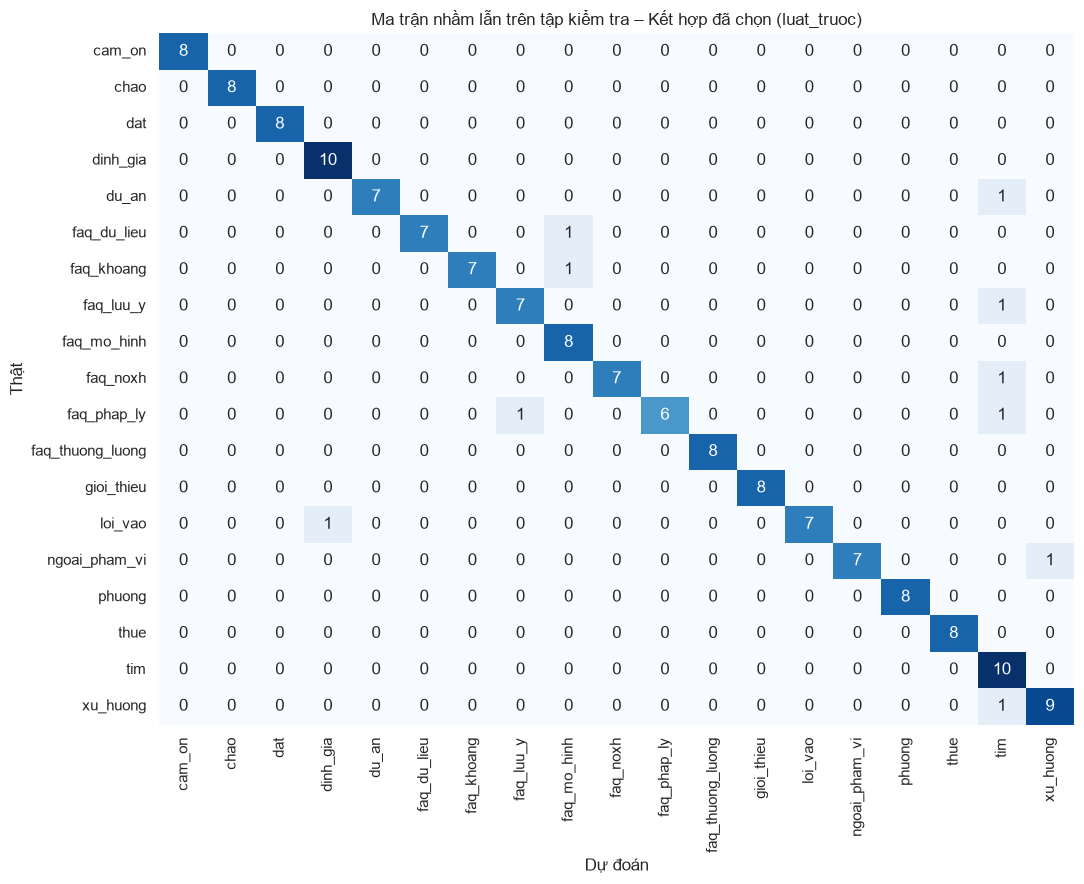

Các câu còn sai (10/158):


,cau_hoi,y_dinh,du_doan,p
53,mua nha bay gio co bi hớ khong,xu_huong,tim,0.46
57,hẻm xe hơi so với hẻm xe máy chênh giá thế nào,loi_vao,dinh_gia,0.87
75,danh sach chung cu,du_an,tim,0.74
95,mua nha giay tay co sao khong,faq_phap_ly,tim,0.67
99,phap ly can kiem tra nhung gi,faq_phap_ly,faq_luu_y,0.87
107,thu nhap bao nhieu duoc mua nha o xa hoi,faq_noxh,tim,0.98
123,khoang tin cay 80 phan tram dung de lam gi,faq_khoang,faq_mo_hinh,0.83
132,so lieu co dang tin khong,faq_du_lieu,faq_mo_hinh,0.93
148,mua nha cu can xem nhung gi,faq_luu_y,tim,0.93
152,gia vang sjc,ngoai_pham_vi,xu_huong,0.16


In [6]:
cuoi = list(du.values())[-1]
ma_tran = confusion_matrix(nhan(list(that_te)), nhan(cuoi), labels=list(LOP))
plt.figure(figsize=(11, 9))
sns.heatmap(ma_tran, annot=True, fmt="d", cmap="Blues", xticklabels=LOP, yticklabels=LOP, cbar=False)
plt.title(f"Ma trận nhầm lẫn trên tập kiểm tra – {list(du)[-1]}"); plt.xlabel("Dự đoán"); plt.ylabel("Thật")
plt.tight_layout(); plt.show()
sai = test.assign(du_doan=nhan(cuoi), p=P_TE.max(1).round(2))[[a != b for a, b in zip(nhan(list(that_te)), nhan(cuoi))]]
print(f"Các câu còn sai ({len(sai)}/{len(test)}):")
display(sai[["cau_hoi", "y_dinh", "du_doan", "p"]])

**Đọc kết quả:**
- So với luật cũ, mô hình hiểu được nhiều cách hỏi hơn hẳn, nhất là câu **không dấu, viết tắt, diễn đạt lạ**: tỷ lệ câu "không nhận ra" giảm từ khoảng 1/4 xuống vài phần trăm.
- Trên tập kiểm tra, **mô hình đơn lẻ còn chính xác hơn chiến lược kết hợp** đã chọn: luật cũ bắt nhầm theo từ khóa (ví dụ câu có chữ "mua nhà" bị hiểu là *tìm nhà* dù đang hỏi về nhà ở xã hội). Chiến lược kết hợp được chọn trên tập huấn luyện, nơi nhiều câu được viết cùng phong cách với luật nên luật có lợi thế. **Không đổi chiến lược theo kết quả tập kiểm tra**, vì như vậy là dùng tập kiểm tra để chọn mô hình, con số kiểm tra sẽ không còn khách quan. Bài học: cần thêm một **tập kiểm định (validation) riêng**, viết theo phong cách người dùng thật, để chọn chiến lược.
- Câu còn sai (bảng trên) chủ yếu là câu ngắn, mơ hồ, hoặc nằm giữa hai ý định gần nhau. Với câu mô hình không chắc, trang web **hỏi lại** người dùng bằng 2–3 gợi ý thay vì trả lời sai.

## Bước 5: Lưu mô hình cho trang web
`model/tro_ly_y_dinh.joblib` chứa bộ đặc trưng TF-IDF, mô hình Logistic Regression, chiến lược kết hợp, câu ví dụ cho từng ý định (dùng làm gợi ý khi hỏi lại), và vài câu mẫu kèm xác suất do Python tính, để kiểm thử tự động xác nhận trình duyệt tính **giống hệt** Python. Script `demo/_build/build_site.py` đọc file này và nhúng tham số vào trang.

In [7]:
import joblib
vi_du = train.groupby("y_dinh")["cau_hoi"].first().to_dict()
vi_du.update({"dinh_gia": "Nhà 1 trệt 1 lầu 80m² hẻm xe hơi giá bao nhiêu?", "tim": "Tìm nhà dưới 3 tỷ rẻ hơn thị trường",
              "xu_huong": "Giá nhà Phú Hòa 6–12 tháng tới tăng hay giảm?", "dat": "Lô đất 5x20 hẻm xe hơi Phú Hòa giá bao nhiêu?",
              "thue": "Nhà 80m² 1 trệt 1 lầu cho thuê được bao nhiêu?"})
mau = [{"cau": c, "p": [round(float(x), 6) for x in LR.predict_proba(DT.transform([chuan_hoa(c)]))[0]]} for c in test["cau_hoi"].iloc[::20]]
joblib.dump({"dac_trung": DT, "mo_hinh": LR, "chien_luoc": CHIEN_LUOC, "nguong": TAU, "vi_du": vi_du, "mau": mau,
             "ket_qua_kiem_tra": KQ_TE.round(2).to_dict()}, MODEL_DIR / "tro_ly_y_dinh.joblib")
print("Đã lưu model/tro_ly_y_dinh.joblib ·", sum(len(v.vocabulary_) for _, v in DT.transformer_list), "đặc trưng ·", len(LOP), "ý định")

Đã lưu model/tro_ly_y_dinh.joblib · 2609 đặc trưng · 19 ý định


## Kết luận
- Trợ lý chuyển từ **luật viết tay** sang **mô hình học có giám sát** (TF-IDF + Logistic Regression), được chọn và đánh giá đúng quy trình: kiểm định chéo trên tập huấn luyện, tập kiểm tra viết riêng chỉ dùng một lần.
- Mô hình chạy ngay trên trình duyệt (không gửi câu hỏi đi đâu, không cần khóa API). Khi không chắc, trợ lý hỏi lại thay vì trả lời bừa.
- **Hạn chế:** câu huấn luyện do người làm đề tài viết, chưa phải câu hỏi thật của người dùng; trợ lý chỉ **phân loại ý định** rồi trả lời bằng các hàm có sẵn, không tự sinh câu trả lời tự do như các mô hình ngôn ngữ lớn. Muốn tốt hơn: thu thập câu hỏi thật của người dùng (có đồng ý) rồi gán nhãn bổ sung.